# 01 · Define the question and invent a dataset

We are prototyping **training and inference mechanics**, using an invented TKA example. Nothing here establishes whether any angle improves actual patient outcomes.

The project chats started with TKA/THA outcome prediction and moved toward continuous implant-position optimization. We start with **three TKA angles**, a fixed implant family, and one synthetic 12-month FJS-like target. Bone datums are represented by scalar preoperative measurements; CT processing and physical implant generation are future adapters.

**Question:** for patients with pretreatment profile X, what is the expected difference in the outcome if executed positions change from a reference vector to a candidate vector?

`X, W → executed plan T → outcome Y`, with `X, W → Y` as well. W represents measured treatment-selection context. X determines effect heterogeneity. Postoperative recovery information must not be put into baseline X/W.

The code treats candidate settings as interventions on executed positions. Translating a requested plan into achieved positions needs a separate execution model later.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works when Jupyter starts in the repository root or notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
ARTIFACTS = ROOT / "artifacts" / "notebooks"
ARTIFACTS.mkdir(parents=True, exist_ok=True)
SEED = 42
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False})
print("SYNTHETIC ONLY — no clinical conclusions.")

SYNTHETIC ONLY — no clinical conclusions.


In [2]:
from plan_ml_poc.schema import X_COLUMNS, W_COLUMNS, PLAN_COLUMNS, OUTCOME, REFERENCE
from plan_ml_poc.synthetic import make_cases, true_mean
from plan_ml_poc.training import split_cases

cases = make_cases(n=3000, seed=SEED)
train, test = split_cases(cases, seed=SEED)
print({"training_cases": len(train), "held_out_cases": len(test)})
cases.head()

/private/tmp/plan-ml-poc-build/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'training_cases': 2400, 'held_out_cases': 600}


,patient_id,age,bmi,baseline_function,preop_hka_deg,mldfa_deg,mpta_deg,surgeon_b,hospital_b,femoral_varus_deg,tibial_varus_deg,tibial_slope_deg,synthetic_fjs_12mo
0,synthetic-00000,73.218681,28.083177,66.136906,2.368416,84.347596,92.280601,1,1,1.019474,-0.072458,0.877771,73.861375
1,synthetic-00001,72.834191,33.290965,33.265113,-0.595369,86.837182,91.840885,0,1,1.003567,1.219321,5.738393,61.887599
2,synthetic-00002,69.315954,33.841424,47.453639,-3.273135,88.491263,84.074355,0,0,-1.234667,2.706351,3.445593,66.045974
3,synthetic-00003,74.828935,30.974966,61.613948,-1.745688,92.236282,91.538090,1,0,-0.451255,2.388144,0.573495,71.721872
4,synthetic-00004,73.351505,24.419581,48.502445,-5.474355,84.888605,89.647441,1,1,-2.850057,-2.045545,3.353858,68.559690


## Read the feature roles before fitting

| Role | Example | Available at planning time? |
|---|---|---|
| X: effect modifiers | HKA, mLDFA, MPTA, age, BMI, baseline function | Yes |
| W: adjustment context | Binary surgeon and hospital indicators | Yes |
| T: executed intervention | Femoral varus, tibial varus, tibial slope | Historical training label; candidate at inference |
| Y: target | Synthetic FJS-like outcome at 12 months | Training only |
| Patient ID | Link repeated procedures for grouped splits | Yes; never a predictive input |

`baseline_function` is a generic invented preoperative function measure, not preoperative FJS. We do not implement an FJS questionnaire scoring formula.

Positive coronal angles mean varus in this POC. All angle ranges and coupled constraints are arbitrary teaching choices. Confirm units and coordinate conventions before any real data adapter.

,role,columns
0,X,"[age, bmi, baseline_function, preop_hka_deg, m..."
1,W,"[surgeon_b, hospital_b]"
2,T,"[femoral_varus_deg, tibial_varus_deg, tibial_s..."
3,Y,[synthetic_fjs_12mo]


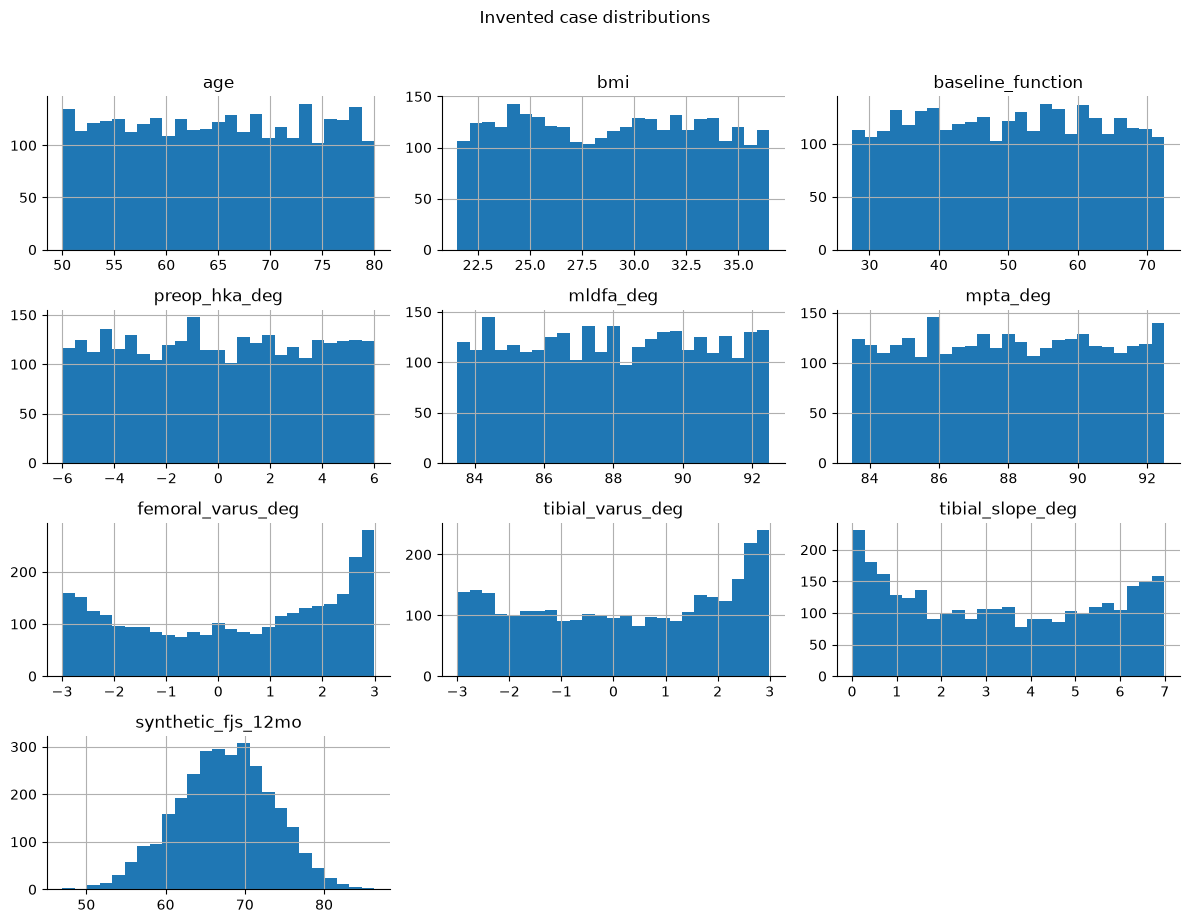

In [3]:
roles = pd.DataFrame({"role": ["X", "W", "T", "Y"],
                      "columns": [X_COLUMNS, W_COLUMNS, PLAN_COLUMNS, [OUTCOME]]})
display(roles)
assert set(train.patient_id).isdisjoint(test.patient_id)
cases[X_COLUMNS + PLAN_COLUMNS + [OUTCOME]].hist(bins=25, figsize=(12, 9))
plt.suptitle("Invented case distributions", y=1.02)
plt.tight_layout()
plt.show()

## The simulator gives us an oracle — real data will not

Treatment selection depends on patient anatomy and care context; it is observational rather than randomized. Independent noise leaves residual angle variation.

We authored a quadratic response with angle interactions and linear X-dependent coefficients. This deliberately matches our EconML model family, making the tutorial easier than a real study. Oracle values live in `synthetic.py`; the training and search modules do not import them. The outcome noise is bounded, so we do not clip the response and silently change the estimand.

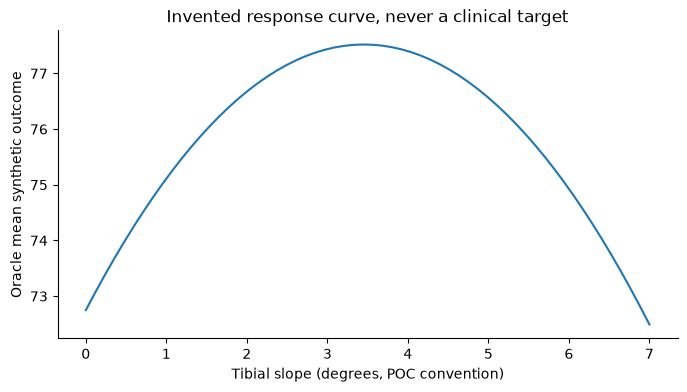

In [4]:
patient = cases.iloc[[0]]
slopes = np.linspace(0, 7, 60)
plans = np.tile(REFERENCE, (len(slopes), 1))
plans[:, 2] = slopes
repeated = pd.concat([patient] * len(plans), ignore_index=True)
plt.plot(slopes, true_mean(repeated, plans))
plt.xlabel("Tibial slope (degrees, POC convention)")
plt.ylabel("Oracle mean synthetic outcome")
plt.title("Invented response curve, never a clinical target")
plt.show()
train.to_csv(ARTIFACTS / "train.csv", index=False)
test.to_csv(ARTIFACTS / "test.csv", index=False)

**Try next:** change the sample size and random seed. Later, use notebook 04 to break the no-unmeasured-confounding assumption. Inspect `src/plan_ml_poc/synthetic.py` to see every invented relationship.